# Convolutional Neural Networks (CNNs)

## Import Dependencies

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np

## Device Cofiguration

In [2]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

## Define Hyperparameters

In [18]:
num_epochs = 100
batch_size = 4
learning_rate = 0.001

## Import and Prepare Dataset

CIFAR10 Datset

In [5]:
transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])]
)

train_dataset = torchvision.datasets.CIFAR10(root="./data", train=True, download=True, transform=transform)
test_dataset = torchvision.datasets.CIFAR10(root="./data", train=True, download=True, transform=transform)

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

examples = iter(train_loader)
samples, labels = next(examples)
samples.shape, labels.shape

(torch.Size([4, 3, 32, 32]), torch.Size([4]))

## Visualize the Images

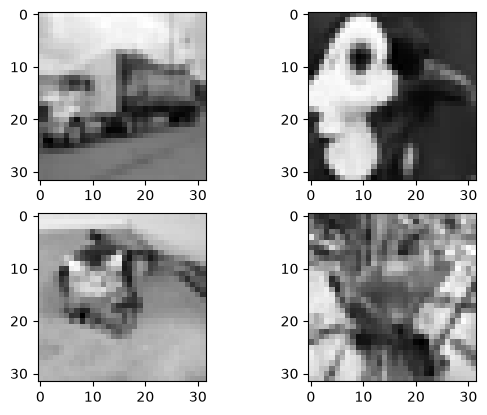

In [7]:
for i in range(4):
    plt.subplot(2, 2, i+1)
    plt.imshow(samples[i][0], cmap='gray')
plt.show()

## Implement CNN

Formula to determine output size:

$$
\frac{W - F + 2P}{S} + 1
$$

where:

- $W$: Input width
- $F$: Filter size
- $P$: Padding size
- $S$: Stride

In [10]:
class ConvNet(nn.Module):
    def __init__(self):
        super(ConvNet, self).__init__()
        self.conv1 = nn.Conv2d(3, 6, 5) # in_channels, out_channels, kernel_size (optional: stride, padding)
        self.pool = nn.MaxPool2d(2, 2) # kernel_size, stride
        self.conv2 = nn.Conv2d(6, 16, 5)
        self.fc1 = nn.Linear(16*5*5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(-1, 16*5*5)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x

model = ConvNet().to(device)

## Define Loss and Optimizer

In [11]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)

## Training Loop

In [19]:
n_total_steps = len(train_loader)

for epoch in range(num_epochs):
    for i, (images, labels) in enumerate(train_loader):
        # (4, 3, 32, 32) -> (4, 3, 1024)
        images = images.to(device)
        labels = labels.to(device)

        # forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)

        # backward pass
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    print(f"Epoch {epoch+1}: Loss = {loss.item()}")

print('Finished training.')

Epoch 1: Loss = 1.26426362991333
Epoch 2: Loss = 1.3831980228424072
Epoch 3: Loss = 1.0255956649780273
Epoch 4: Loss = 0.6125750541687012
Epoch 5: Loss = 0.5049152970314026
Epoch 6: Loss = 1.3342541456222534
Epoch 7: Loss = 1.7495899200439453
Epoch 8: Loss = 2.241024971008301
Epoch 9: Loss = 0.36872464418411255
Epoch 10: Loss = 0.6329598426818848
Epoch 11: Loss = 0.44517025351524353
Epoch 12: Loss = 0.5858069658279419
Epoch 13: Loss = 1.416729211807251
Epoch 14: Loss = 1.488002061843872
Epoch 15: Loss = 0.2876920700073242
Epoch 16: Loss = 1.545734167098999
Epoch 17: Loss = 0.9637176990509033
Epoch 18: Loss = 0.2715320885181427
Epoch 19: Loss = 1.8139610290527344
Epoch 20: Loss = 0.2662651538848877
Epoch 21: Loss = 1.498226523399353
Epoch 22: Loss = 1.0792357921600342
Epoch 23: Loss = 0.7776660919189453
Epoch 24: Loss = 1.1778255701065063
Epoch 25: Loss = 0.5259655714035034
Epoch 26: Loss = 2.651859760284424
Epoch 27: Loss = 0.9002875685691833
Epoch 28: Loss = 0.9854851961135864
Epoch 2

## Test and Evaluation

In [22]:
with torch.no_grad():
    test_loss = 0
    n_correct = 0
    n_samples = 0
    n_class_correct = [0 for i in range(10)]
    n_class_samples = [0 for i in range(10)]
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)
        outputs = model(images)
        test_loss += criterion(outputs, labels)

        _, predicted = torch.max(outputs, 1)
        n_samples += labels.shape[0]
        n_correct += (predicted == labels).sum().item()

        for i in range(batch_size):
            label = labels[i]
            pred = predicted[i]
            if (label == pred):
                n_class_correct[label] += 1
            n_class_samples[label] += 1

    test_loss = test_loss / n_samples
    print(f"Test loss: {loss.item()}")
    
    acc = 100.0 * n_correct / n_samples
    print(f"Accuracy of the network: {acc} %")

    for i in range(10):
        acc = 100.0 * n_class_correct[i] / n_class_samples[i]
        print(f'Accuracy of {classes[i]}: {acc} %')

Test loss: 0.051711827516555786
Accuracy of the network: 93.592 %
Accuracy of plane: 92.02 %
Accuracy of car: 99.08 %
Accuracy of bird: 99.1 %
Accuracy of cat: 88.76 %
Accuracy of deer: 91.22 %
Accuracy of dog: 85.66 %
Accuracy of frog: 94.96 %
Accuracy of horse: 93.16 %
Accuracy of ship: 96.98 %
Accuracy of truck: 94.98 %
